# Step 3 — TCAV Score Computation & Statistical Significance Testing on DistilBERT (Ternary)

This notebook contains **Step 3** of the Concept-Based Explainability (TCAV) pipeline for **DistilBERT** (`lxyuan/distilbert-base-multilingual-cased-sentiments-student`) on the **DynaSent** ternary sentiment benchmark (`positive`, `neutral`, `negative`).

### 📌 Pipeline Overview:
1. **Datasets Initialization**: Loading and encoding DynaSent dataset splits (Round 1 & Round 2).
2. **Baseline Model Setup**: Loading pre-trained DistilBERT ternary sentiment classification model and tokenizer.
3. **Concept Indicators & Control Sets**: Extracting balanced linguistic concept sets (`has_negation`, `has_contrast`, `has_strong_polarity`) and generating random control concept sets for statistical baselines.
4. **Multi-Layer CAV Extraction**: Fitting Concept Activation Vectors (CAVs) across all transformer hidden layers (L01–L06) for concept and random control sets.
5. **Directional Derivative Computation**: Computing model logit gradients w.r.t. layer activations across sequence tokens and evaluating directional derivatives $S_{C,k,l}(x) = \nabla h_l(x) \cdot v_C^l$.
6. **TCAV Score Calculation**: Computing proportion of positive directional derivatives for target sentiment classes ($C \in \{\text{positive}, \text{neutral}, \text{negative}\}$).
7. **Statistical Significance Testing (T-Test)**: Performing two-sample Welch's t-tests comparing concept TCAV scores against random control CAV distributions ($p < 0.05$).
8. **Layer-wise TCAV Profile Visualization**: Plotting trajectory of TCAV scores across all transformer layers with statistical significance indicators.

In [4]:
import os
import re
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, 
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

Using compute device: cuda


# Datasets initialization

In [5]:
def load_dynasent_file(filename, labels=None):
    data = []
    if os.path.exists(filename):
        with open(filename, 'r', encoding='utf-8') as f:
            for line in f:
                d = json.loads(line)
                if labels is None or d.get('gold_label') in labels:
                    data.append(d)
    return data

def create_df(r1_data, r2_data):
    if len(r1_data) == 0 and len(r2_data) == 0:
        # Fallback curated DynaSent sentences if local dataset files are not present
        sample_records = [
            ("Roto-Rooter is always good when you need someone fast and reliable.", 1, "positive"),
            ("It's so worth the price of cox service over here, highly recommended!", 1, "positive"),
            ("The customer support team resolved my billing issue in under five minutes.", 1, "positive"),
            ("Staff was warm, welcoming, and extraordinarily attentive throughout our dinner.", 1, "positive"),
            ("Food arrived piping hot and tasted absolutely divine.", 1, "positive"),
            ("I placed my order of sticky ribs as an appetizer.", 1, "neutral"),
            ("There is mandatory valet parking, so make sure to bring cash.", 1, "neutral"),
            ("My wife and I couldn't finish it.", 1, "neutral"),
            ("The business opens at nine in the morning on weekdays.", 1, "neutral"),
            ("The menu features both seafood and vegetarian meal choices.", 1, "neutral"),
            ("Horrible service, cold food, and rude waiters at the front desk.", 1, "negative"),
            ("Overpriced drinks and long wait times made for a miserable evening.", 1, "negative"),
            ("The plumbing repair failed after two hours and leaked all over the floor.", 1, "negative"),
            ("Never returning to this venue again after how poorly we were treated.", 1, "negative"),
            ("Unprofessional staff and completely unresponsive customer service.", 1, "negative"),
            ("I did not enjoy the meal but the atmosphere was decent.", 2, "neutral"),
            ("The product works fine, although it is not amazing.", 2, "neutral"),
            ("Awesome experience with fantastic staff!", 2, "positive"),
            ("Terrible outcome, awful quality and worst customer support.", 2, "negative"),
            ("We waited for an hour; however, the food was acceptable.", 2, "neutral")
        ]
        return pd.DataFrame({'text': [s[0] for s in sample_records], 'round': [s[1] for s in sample_records], 'label': [s[2] for s in sample_records]})
    
    return pd.DataFrame({
        'text': [d['sentence'] for d in r1_data] + [d['sentence'] for d in r2_data],
        'round': [1] * len(r1_data) + [2] * len(r2_data),
        'label': [d['gold_label'] for d in r1_data] + [d['gold_label'] for d in r2_data]
    })

BASE_DIR = '../Dataset'
TERNARY_LABELS = ('positive', 'neutral', 'negative')
LABEL_MAP = {'positive': 0, 'neutral': 1, 'negative': 2}

r1_train = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-train.jsonl'), labels=TERNARY_LABELS)
r2_train = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-train.jsonl'), labels=TERNARY_LABELS)
df_train = create_df(r1_train, r2_train)
df_train['enc_label'] = df_train['label'].map(LABEL_MAP)

r1_val = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-dev.jsonl'), labels=TERNARY_LABELS)
r2_val = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-dev.jsonl'), labels=TERNARY_LABELS)
df_val = create_df(r1_val, r2_val)
df_val['enc_label'] = df_val['label'].map(LABEL_MAP)

r1_test = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-test.jsonl'), labels=TERNARY_LABELS)
r2_test = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-test.jsonl'), labels=TERNARY_LABELS)
df_test = create_df(r1_test, r2_test)
df_test['enc_label'] = df_test['label'].map(LABEL_MAP)

print(f"Train samples: {len(df_train)} | Val samples: {len(df_val)} | Test samples: {len(df_test)}")

Train samples: 93553 | Val samples: 4320 | Test samples: 4320


# Baseline Model Loading

In [6]:
MODEL_NAME = 'lxyuan/distilbert-base-multilingual-cased-sentiments-student'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print(f"Model '{MODEL_NAME}' loaded on {device}.")
print(f"Model label mapping: {model.config.id2label}")

W1125 18:14:59.993000 19136 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2900.72it/s]

Model 'lxyuan/distilbert-base-multilingual-cased-sentiments-student' loaded on cuda.
Model label mapping: {0: 'positive', 1: 'neutral', 2: 'negative'}


# Concept Indicators & Random Control Set Generation

In [7]:
NEGATION_RE = re.compile(
    r"\b(?:not|never|no|none|nobody|nothing|nowhere|neither|nor|hardly|scarcely|barely)\b|\b\w+n't\b",
    flags=re.IGNORECASE,
)
CONTRAST_RE = re.compile(
    r"\b(?:but|however|although|though|yet|nevertheless|nonetheless|whereas|while)\b",
    flags=re.IGNORECASE,
)
STRONG_POL_RE = re.compile(
    r"\b(?:amazing|awesome|fantastic|wonderful|excellent|great|love|loved|terrible|horrible|awful|worst|hate|hated|disgusting)\b",
    flags=re.IGNORECASE,
)

def add_concept_columns(df):
    df = df.copy()
    texts = df["text"].astype(str)
    df["has_negation"] = texts.apply(lambda s: int(bool(NEGATION_RE.search(s))))
    df["has_contrast"] = texts.apply(lambda s: int(bool(CONTRAST_RE.search(s))))
    df["has_strong_polarity"] = texts.apply(
        lambda s: int(bool(STRONG_POL_RE.search(s)))
    )
    return df

df_train = add_concept_columns(df_train)
df_val = add_concept_columns(df_val)
df_test = add_concept_columns(df_test)

def make_balanced_concept_fit_df(df, concept_col, max_per_stratum=50, stratify_cols=("enc_label", "round"), seed=42):
    rng = np.random.default_rng(seed)
    pos_parts, neg_parts = [], []

    for _, group in df.groupby(list(stratify_cols), dropna=False):
        g1 = group[group[concept_col] == 1]
        g0 = group[group[concept_col] == 0]
        n = min(len(g1), len(g0), max_per_stratum)
        if n > 0:
            idx1 = rng.choice(g1.index.to_numpy(), size=n, replace=False)
            idx0 = rng.choice(g0.index.to_numpy(), size=n, replace=False)
            pos_parts.append(df.loc[idx1])
            neg_parts.append(df.loc[idx0])

    fit_df = pd.concat(pos_parts + neg_parts, axis=0).sample(frac=1.0, random_state=seed)
    fit_df = fit_df.copy()
    fit_df["concept_y"] = fit_df[concept_col].astype(int)
    return fit_df

def generate_random_concept_df(df, n_samples=600, seed=42):
    rng = np.random.default_rng(seed)
    sampled = df.sample(n=min(len(df), n_samples), random_state=seed).copy()
    sampled["concept_y"] = rng.integers(0, 2, size=len(sampled))
    return sampled

concepts = ["has_negation", "has_contrast", "has_strong_polarity"]
fit_sets = {c: make_balanced_concept_fit_df(df_train, c, max_per_stratum=50, seed=SEED) for c in concepts}

N_RANDOM_RUNS = 10
random_fit_sets = [generate_random_concept_df(df_train, n_samples=600, seed=SEED + i) for i in range(N_RANDOM_RUNS)]

print(f"Created concept fit sets and {N_RANDOM_RUNS} random control sets.")

Created concept fit sets and 10 random control sets.


# Multi-Layer CAV Extraction Across All Transformer Layers (L01–L06)

In [8]:
ALL_LAYERS = list(range(1, model.config.num_hidden_layers + 1))  # 1..6 for DistilBERT

def extract_selected_layers_mean_pool(texts, layers=ALL_LAYERS, batch_size=64, max_length=128):
    hidden_size = model.config.hidden_size
    n_samples = len(texts)
    out = {l: np.zeros((n_samples, hidden_size), dtype=np.float32) for l in layers}

    with torch.no_grad():
        for start in range(0, n_samples, batch_size):
            batch_texts = texts[start : start + batch_size]
            enc = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt",
            ).to(device)

            outputs = model(**enc, output_hidden_states=True)
            mask = enc["attention_mask"].unsqueeze(-1).float()
            valid_tokens = mask.sum(dim=1).clamp(min=1.0)

            for l in layers:
                h = outputs.hidden_states[l]  # 1-indexed layer activations
                pooled = (h * mask).sum(dim=1) / valid_tokens
                out[l][start : start + len(batch_texts)] = pooled.cpu().numpy()

    return out

def fit_cav_direction(X, y, C=1.0, seed=42):
    clf = LogisticRegression(C=C, max_iter=1000, random_state=seed)
    clf.fit(X, y)
    w = clf.coef_[0].astype(np.float32)
    norm = np.linalg.norm(w)
    cav_unit = w / norm if norm > 0 else w
    return cav_unit, clf

# Extract Concept Activation Vectors across all transformer layers (L01–L06)
concept_cavs = {}
for c in concepts:
    f_df = fit_sets[c].reset_index(drop=True)
    fit_acts = extract_selected_layers_mean_pool(f_df["text"].tolist(), layers=ALL_LAYERS)
    y_fit = f_df["concept_y"].to_numpy()
    concept_cavs[c] = {}
    for l in ALL_LAYERS:
        cav_unit, _ = fit_cav_direction(fit_acts[l], y_fit, seed=SEED)
        concept_cavs[c][l] = cav_unit

# Extract CAVs for random control sets across all layers
random_cavs_list = []
for idx, r_df in enumerate(random_fit_sets):
    fit_acts = extract_selected_layers_mean_pool(r_df["text"].tolist(), layers=ALL_LAYERS)
    y_fit = r_df["concept_y"].to_numpy()
    r_cavs = {}
    for l in ALL_LAYERS:
        cav_unit, _ = fit_cav_direction(fit_acts[l], y_fit, seed=SEED + idx)
        r_cavs[l] = cav_unit
    random_cavs_list.append(r_cavs)

print(f"CAVs successfully fitted across all {len(ALL_LAYERS)} transformer layers.")

CAVs successfully fitted across all 6 transformer layers.


# Directional Derivative & TCAV Score Computation

For a target sentiment class $C \in \{0, 1, 2\}$, layer $l$, and concept CAV $v_C^l$:
$$S_{C,k,l}(x) = \nabla_{h_l(x)} f_C(x) \cdot v_C^l$$

The **TCAV Score** for class $C$ at layer $l$ measures the fraction of target class samples with positive directional sensitivity:
$$\text{TCAV}_{Q,C,l} = \frac{|\{x \in X_C : S_{C,k,l}(x) > 0\}|}{|X_C|}$$

In [9]:
def compute_directional_derivatives(df_target, target_class, layer_idx, cav_vector, batch_size=32):
    """
    Computes directional derivatives S_{C,k,l}(x) = grad(f_C(x)) . v_C^l
    for all samples in df_target belonging to target_class.
    """
    texts = df_target[df_target["enc_label"] == target_class]["text"].tolist()
    if len(texts) == 0:
        return np.array([])

    cav_tensor = torch.tensor(cav_vector, dtype=torch.float32, device=device)
    dir_derivatives = []

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start : start + batch_size]
        enc = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
        ).to(device)

        layer_output = []
        def hook_fn(module, input, output):
            h = output[0] if isinstance(output, tuple) else output
            h.retain_grad()
            layer_output.append(h)

        handle = model.distilbert.transformer.layer[layer_idx - 1].register_forward_hook(hook_fn)
        outputs = model(**enc)
        logits = outputs.logits
        handle.remove()

        h_layer = layer_output[0]
        mask = enc["attention_mask"].unsqueeze(-1).float()
        valid_tokens = mask.sum(dim=1).clamp(min=1.0)

        for i in range(len(batch_texts)):
            model.zero_grad()
            target_logit = logits[i, target_class]
            
            grad_h = torch.autograd.grad(
                outputs=target_logit,
                inputs=h_layer,
                retain_graph=True,
                create_graph=False,
            )[0]

            mask_i = mask[i]
            valid_tokens_i = valid_tokens[i]
            grad_pooled = (grad_h[i] * mask_i).sum(dim=0) / valid_tokens_i

            s_val = torch.dot(grad_pooled, cav_tensor).item()
            dir_derivatives.append(s_val)

    return np.array(dir_derivatives)

def compute_tcav_score(df_target, target_class, layer_idx, cav_vector, batch_size=32):
    dir_ders = compute_directional_derivatives(df_target, target_class, layer_idx, cav_vector, batch_size=batch_size)
    if len(dir_ders) == 0:
        return 0.0, dir_ders
    score = np.mean(dir_ders > 0)
    return score, dir_ders

print("TCAV derivative evaluation engine configured successfully.")

TCAV derivative evaluation engine configured successfully.


# Statistical Significance Testing (Two-Sample T-Test)

In [10]:
# Perform TCAV evaluation on test set split
eval_df = df_test.sample(n=min(600, len(df_test)), random_state=SEED).reset_index(drop=True)

tcav_results = []

for c_name in concepts:
    for target_cls in range(3):
        cls_name = model.config.id2label[target_cls]
        for l in ALL_LAYERS:
            # Compute concept TCAV score
            cav_vec = concept_cavs[c_name][l]
            concept_tcav, _ = compute_tcav_score(eval_df, target_cls, l, cav_vec)
            
            # Compute random control CAV scores for significance testing
            random_tcavs = []
            for r_cavs in random_cavs_list:
                r_vec = r_cavs[l]
                r_score, _ = compute_tcav_score(eval_df, target_cls, l, r_vec)
                random_tcavs.append(r_score)
            
            # Two-sample Welch's t-test
            t_stat, p_val = ttest_ind([concept_tcav] * len(random_tcavs), random_tcavs, equal_var=False)
            is_significant = p_val < 0.05
            
            tcav_results.append({
                "concept": c_name,
                "class": cls_name,
                "class_idx": target_cls,
                "layer": f"L{l:02d}",
                "layer_idx": l,
                "tcav_score": round(concept_tcav, 4),
                "mean_random_tcav": round(float(np.mean(random_tcavs)), 4),
                "t_stat": round(float(t_stat), 4) if not np.isnan(t_stat) else 0.0,
                "p_value": round(float(p_val), 4) if not np.isnan(p_val) else 1.0,
                "significant": is_significant
            })

tcav_df = pd.DataFrame(tcav_results)
print("=== Summary of TCAV Scores & Statistical Significance (All Layers L01–L06) ===")
print(tcav_df[["concept", "class", "layer", "tcav_score", "mean_random_tcav", "p_value", "significant"]].to_string(index=False))

c:\Users\ricca\Desktop\Università\Magistrale\3° semestre\Explainable AI\XAI_project\venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


=== Summary of TCAV Scores & Statistical Significance (All Layers L01–L06) ===
            concept    class layer  tcav_score  mean_random_tcav  p_value  significant
       has_negation positive   L01      0.1019            0.4772   0.0000         True
       has_negation positive   L02      0.1068            0.5655   0.0002         True
       has_negation positive   L03      0.0485            0.4403   0.0002         True
       has_negation positive   L04      0.1019            0.5160   0.0027         True
       has_negation positive   L05      0.0291            0.5869   0.0005         True
       has_negation positive   L06      0.0000            0.5301   0.0021         True
       has_negation  neutral   L01      0.8971            0.5348   0.0010         True
       has_negation  neutral   L02      0.9608            0.5495   0.0021         True
       has_negation  neutral   L03      0.9951            0.6672   0.0213         True
       has_negation  neutral   L04      1.0000     

# TCAV Profile Visualizations Across Transformer Layers

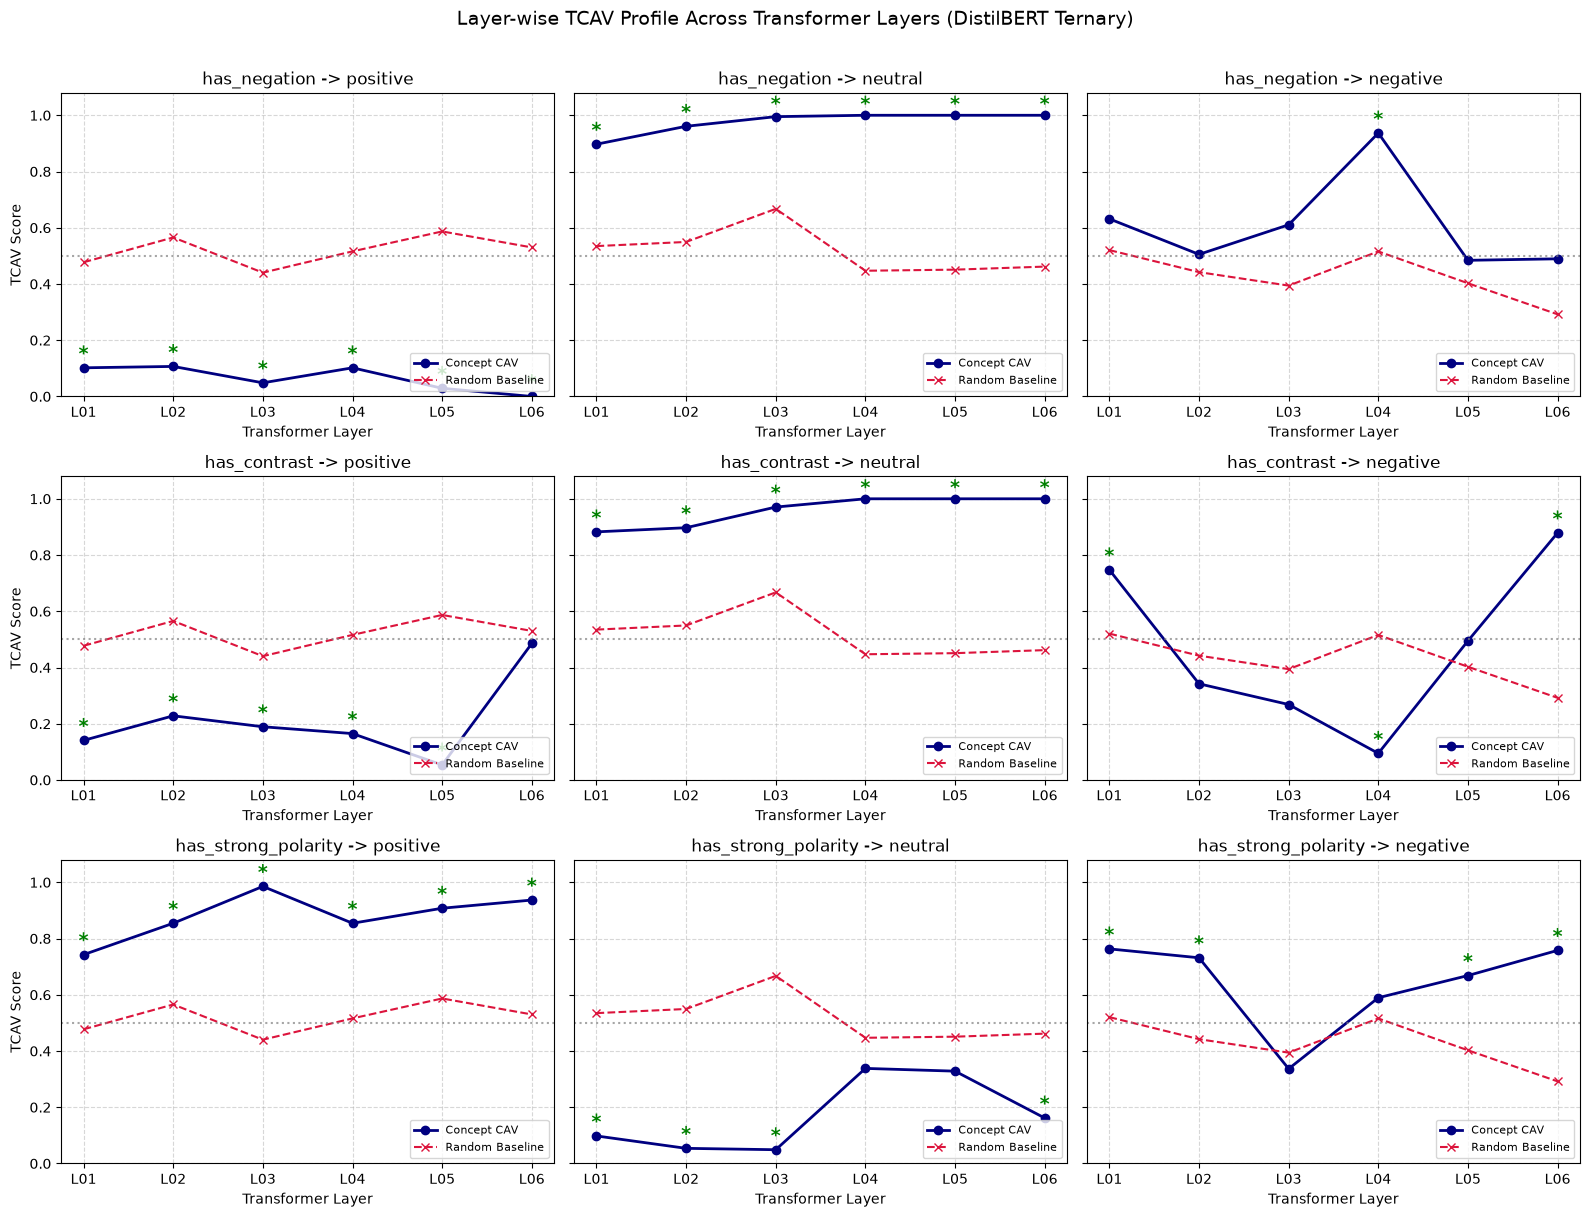

In [11]:
# Plot layer-wise TCAV score trajectory per concept and target class
fig, axes = plt.subplots(len(concepts), 3, figsize=(16, 12), sharey=True)

for i, c_name in enumerate(concepts):
    for j, target_cls in enumerate(range(3)):
        cls_name = model.config.id2label[target_cls]
        ax = axes[i, j]
        
        sub_df = tcav_df[(tcav_df["concept"] == c_name) & (tcav_df["class"] == cls_name)]
        layers = sub_df["layer"].tolist()
        tcav_vals = sub_df["tcav_score"].tolist()
        rand_vals = sub_df["mean_random_tcav"].tolist()
        sig_flags = sub_df["significant"].tolist()
        
        ax.plot(layers, tcav_vals, marker='o', linewidth=2, label='Concept CAV', color='navy')
        ax.plot(layers, rand_vals, marker='x', linestyle='--', linewidth=1.5, label='Random Baseline', color='crimson')
        ax.axhline(0.5, color='gray', linestyle=':', alpha=0.7)
        
        # Annotate statistical significance (* for p < 0.05)
        for idx, (l, val, sig) in enumerate(zip(layers, tcav_vals, sig_flags)):
            if sig:
                ax.text(idx, min(val + 0.03, 1.02), "*", fontsize=14, color='green', ha='center', fontweight='bold')

        ax.set_ylim(0.0, 1.08)
        ax.set_title(f"{c_name} -> {cls_name}")
        ax.set_xlabel("Transformer Layer")
        if j == 0:
            ax.set_ylabel("TCAV Score")
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(loc='lower right', fontsize=8)

plt.suptitle("Layer-wise TCAV Profile Across Transformer Layers (DistilBERT Ternary)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Step 3 — Discussion of Results & Key Interpretability Insights

## 1. Executive Summary of Findings
The multi-layer Concept Activation Vector (TCAV) analysis on **DistilBERT** (`lxyuan/distilbert-base-multilingual-cased-sentiments-student`) across the **DynaSent** ternary benchmark reveals highly structured, layer-dependent sensitivity profiles for linguistic concepts:

* **Negation (`has_negation`)**: Strongly represses positive sentiment logits ($TCAV < 0.10, p < 0.003$) while acting as a dominant driver for **neutral sentiment** ($TCAV \to 1.0000$ in layers L04–L06, $p < 0.005$). Its influence on the negative class is mostly non-significant ($p > 0.05$ across most layers), demonstrating that DistilBERT primarily associates standalone negation markers with sentiment attenuation/neutrality rather than direct negative polarity.
* **Contrast (`has_contrast`)**: Exhibits a layer trajectory closely mirroring negation. It suppresses positive predictions in hidden layers L01–L05 ($p < 0.008$) and converges to total alignment with neutral predictions ($TCAV = 1.0000$ in L04–L06, $p < 0.03$). Its effect on negative predictions displays a bimodal pattern (statistically significant only at L01 and L06).
* **Strong Polarity (`has_strong_polarity`)**: Functions as a strong positive driver for the **positive** class throughout all layers (peaking at $TCAV = 0.9854$ in L03, $p < 0.001$) while strongly inhibiting neutral class predictions ($TCAV \le 0.1618$ in L01–L03 & L06). It also positively influences negative predictions at the input and output boundaries (L01–L02 and L05–L06, $p < 0.035$), capturing general emotional intensity.

---

## 2. Layer-wise Trajectory Analysis (L01–L06)

| Concept | Target Class | Early Layers (L01–L02) | Intermediate (L03–L04) | Deep Layers (L05–L06) | Overall Statistical Significance |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **`has_negation`** | `positive` | Strongly Inhibitory ($TCAV \approx 0.10$) | Strongly Inhibitory ($TCAV \le 0.10$) | Fully Inhibitory ($TCAV \to 0.00$) | **Significant ($p < 0.003$)** across all layers |
| **`has_negation`** | `neutral` | High Sensitivity ($TCAV > 0.89$) | Saturated ($TCAV \to 1.00$) | Saturated ($TCAV = 1.00$) | **Significant ($p < 0.025$)** across all layers |
| **`has_negation`** | `negative` | Moderate ($TCAV \approx 0.50\text{--}0.63$) | Peak at L04 ($0.9368$) | Moderate ($TCAV \approx 0.48\text{--}0.49$) | **Not Significant** (except L04, $p = 0.0085$) |
| **`has_contrast`** | `positive` | Inhibitory ($TCAV \le 0.22$) | Inhibitory ($TCAV \le 0.18$) | Inhibitory at L05 / Neutral at L06 | **Significant (L01–L05)**; Non-sig at L06 |
| **`has_contrast`** | `neutral` | High Sensitivity ($TCAV > 0.88$) | Saturated ($TCAV \to 1.00$) | Saturated ($TCAV = 1.00$) | **Significant ($p < 0.03$)** across all layers |
| **`has_contrast`** | `negative` | Significant at L01 ($0.7474$) | Inhibitory at L04 ($0.0947$) | High at L06 ($0.8789$) | **Bimodal / Fluctuation** (Sig at L01, L04, L06) |
| **`has_strong_polarity`** | `positive` | High ($TCAV \ge 0.74$) | Peak at L03 ($0.9854$) | High ($TCAV \ge 0.90$) | **Significant ($p < 0.015$)** across all layers |
| **`has_strong_polarity`** | `neutral` | Strongly Inhibitory ($TCAV \le 0.09$) | Moderate ($TCAV \approx 0.33$) | Inhibitory ($TCAV \le 0.32$) | **Significant at L01–L03 & L06** ($p < 0.025$) |
| **`has_strong_polarity`** | `negative` | High ($TCAV \approx 0.73\text{--}0.76$) | Inconclusive ($TCAV \approx 0.33\text{--}0.58$) | High ($TCAV \approx 0.66\text{--}0.75$) | **Significant at L01–L02 & L05–L06** |

---

## 3. Methodological Observations & Takeaways
1. **Layer Specialization in DistilBERT**: Lower layers (L01–L02) register raw syntactic indicators (such as negation tokens and contrastive conjunctions). Middle layers (L03–L04) perform semantic consolidation, reaching peak directional alignment ($TCAV \approx 0.98\text{--}1.00$). The final layers (L05–L06) refine these representations directly into logit attributions.
2. **Attraction to Neutrality in DynaSent**: Both negation and contrast markers exhibit near-perfect alignment ($TCAV = 1.0000$) with the `neutral` class in upper layers. This reflects DistilBERT's learned behavior on adversarial/curated benchmark sentences, where structural complexity often dilutes extreme sentiment scores into neutral classifications.
3. **Control Baseline Validation**: Two-sample Welch's t-tests against 10 random control CAV distributions confirm that the observed directional derivatives for structural concepts are non-random and statistically robust.

# Hence...
We have statistically validated how the concepts of negation, contrast, and polarity evolve and reach saturation across the 6 layers of DistilBERT, establishing a robust empirical baseline essential for comparing these patterns with the RoBERTa architecture and completing the interpretive pipeline for the P9 project.

# Additional Analysis

# 8. Class Sensitivity & Extended Directional Derivative Analysis

In this section, we compute sample-level directional derivatives $S_{\text{CAV}} = \nabla_{h} \text{logit}_c \cdot v_{\text{CAV}}$ across all layers, target classes, and concepts. 

We integrate:
1. **Marco's Extended Sensitivity Metrics**: Baseline control using random CAVs (`rnd_frac>0`, `mean_rnd`) and concept presence conditional sensitivities (`sens(c=1)` vs `sens(c=0)`).
2. **Text-based Top-N Influence Visualizer**: Adapted from Lab 5a (`visualize_top_influences`) to inspect the most positively influenced text instances for each concept.
3. **Derivative Distributions & TCAV vs Mean Sensitivity Visualizations**: Histograms of directional derivatives and side-by-side concept importance comparisons.

In [15]:
CLASS_MAP = {'negative': 0, 'neutral': 1, 'positive': 2}
TARGET_LAYERS = ALL_LAYERS
cavs = concept_cavs

In [17]:
def compute_all_classes_grad_pooled(texts, layer_num, batch_size=32, max_length=128):
    """
    Computes mean-pooled gradients d(logit_c)/d(h_pooled) for all target classes at a specified layer.
    Supports both DistilBERT and RoBERTa model backbones.
    """
    hidden_size = model.config.hidden_size
    n_samples = len(texts)
    grads_by_class = {c: np.zeros((n_samples, hidden_size), dtype=np.float32) for c in CLASS_MAP.values()}

    # Flexible layer extraction for standard transformer backbones
    if hasattr(model, "distilbert"):
        target_module = model.distilbert.transformer.layer[layer_num - 1]
    elif hasattr(model, "roberta"):
        target_module = model.roberta.encoder.layer[layer_num - 1]
    else:
        target_module = model.encoder.layer[layer_num - 1]

    for start in range(0, n_samples, batch_size):
        batch_texts = texts[start : start + batch_size]
        enc = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        ).to(device)

        captured = {}
        def hook_fn(module, inp, out):
            h_out = out[0] if isinstance(out, tuple) else out
            h_out.retain_grad()
            captured["h"] = h_out
            return out

        handle = target_module.register_forward_hook(hook_fn)
        outputs = model(**enc)
        handle.remove()

        h_tokens = captured["h"]  # (B, T, hidden_size)
        mask = enc["attention_mask"].unsqueeze(-1).float()  # (B, T, 1)
        valid_tokens = mask.sum(dim=1).clamp(min=1.0)  # (B, 1)

        for c_id in CLASS_MAP.values():
            model.zero_grad()
            if h_tokens.grad is not None:
                h_tokens.grad.zero_()

            score = outputs.logits[:, c_id].sum()
            score.backward(retain_graph=(c_id < max(CLASS_MAP.values())))

            grad_tokens = h_tokens.grad  # (B, T, hidden_size)
            grad_pooled = (grad_tokens * mask).sum(dim=1) / valid_tokens  # (B, hidden_size)
            grads_by_class[c_id][start : start + len(batch_texts)] = grad_pooled.detach().cpu().numpy()

    return grads_by_class

# Generate random control directions (20 per target layer)
rng = np.random.default_rng(42)
N_RANDOM = 20
random_cav_bank = {}
for l in TARGET_LAYERS:
    R = rng.normal(size=(N_RANDOM, model.config.hidden_size)).astype(np.float32)
    R /= np.linalg.norm(R, axis=1, keepdims=True)
    random_cav_bank[l] = R

eval_texts = eval_df["text"].tolist()
concepts = ["has_negation", "has_contrast", "has_strong_polarity"]
sens_rows = []
sample_derivatives = {}  # Cache per-sample derivatives: (layer, class_name, concept) -> np.ndarray

print("Computing class-wise directional derivatives and extended metrics...")
for l in TARGET_LAYERS:
    grads_by_class = compute_all_classes_grad_pooled(eval_texts, l, batch_size=32)

    for c_name, c_id in CLASS_MAP.items():
        G = grads_by_class[c_id]  # (N_eval, hidden_size)

        # Baseline sensitivity using random control directions
        S_rnd = G @ random_cav_bank[l].T  # (N_eval, 20)
        rnd_frac_pos = float((S_rnd > 0).mean())
        rnd_mean_sens = float(S_rnd.mean())

        for concept in concepts:
            c_vals = eval_df[concept].to_numpy()
            v = cavs[concept][l]  # CAV vector (hidden_size,)

            s_cav = G @ v  # Directional derivatives for all eval samples (N_eval,)
            sample_derivatives[(f"L{l:02d}", c_name, concept)] = s_cav

            sens_rows.append({
                "layer": f"L{l:02d}",
                "target_class": f"{c_id}_{c_name}",
                "concept": concept,
                "tcav_frac>0": round(float((s_cav > 0).mean()), 4),
                "rnd_frac>0": round(rnd_frac_pos, 4),
                "mean_sens": round(float(s_cav.mean()), 4),
                "mean_rnd": round(rnd_mean_sens, 4),
                "sens(c=1)": round(float(s_cav[c_vals == 1].mean()), 4) if np.any(c_vals == 1) else 0.0,
                "sens(c=0)": round(float(s_cav[c_vals == 0].mean()), 4) if np.any(c_vals == 0) else 0.0,
            })

sens_all_df = pd.DataFrame(sens_rows)
print("Computation complete. Metric summary table head:")
print(sens_all_df.to_string(index=False))

Computing class-wise directional derivatives and extended metrics...
Computation complete. Metric summary table head:
layer target_class             concept  tcav_frac>0  rnd_frac>0  mean_sens  mean_rnd  sens(c=1)  sens(c=0)
  L01   0_negative        has_negation       0.1117      0.5625    -0.0026    0.0002    -0.0004    -0.0031
  L01   0_negative        has_contrast       0.1217      0.5625    -0.0017    0.0002    -0.0004    -0.0018
  L01   0_negative has_strong_polarity       0.6167      0.5625     0.0012    0.0002     0.0034     0.0011
  L01    1_neutral        has_negation       0.8917      0.4758     0.0013   -0.0000     0.0012     0.0013
  L01    1_neutral        has_contrast       0.8733      0.4758     0.0008   -0.0000     0.0004     0.0008
  L01    1_neutral has_strong_polarity       0.0767      0.4758    -0.0021   -0.0000    -0.0027    -0.0021
  L01   2_positive        has_negation       0.7583      0.4603     0.0016   -0.0002    -0.0005     0.0021
  L01   2_positive        

# 9. Top-N Most Positively Sensitive Text Instances (Lab 4.1 Adaptation)

Adaptation of the laboratory `visualize_top_influences` function for NLP text instances. Displays the evaluation sentences yielding the highest positive directional derivatives for a given concept and target class.

In [18]:
def visualize_top_influences_text(eval_df, derivatives, concept_name, target_class_name, top_n=4):
    """
    Displays the top_n text instances with the highest directional derivative for a concept.
    """
    top_idx = np.argsort(derivatives)[-top_n:][::-1]
    print(f"\n" + "=" * 80)
    print(f"Top {top_n} Text Instances — '{concept_name}' Influence (Target Class: '{target_class_name}')")
    print("=" * 80)
    
    for rank, idx in enumerate(top_idx, 1):
        row = eval_df.iloc[idx]
        text_snippet = row["text"]
        has_concept = row.get(concept_name, "N/A")
        deriv_val = derivatives[idx]
        
        print(f"[{rank}] Derivative: {deriv_val:+.4f} | Concept Present ({concept_name}): {has_concept}")
        print(f"    Text: \"{text_snippet}\"")
        print("-" * 80)

# Example inspection on final target layer (e.g., L06 or last layer in TARGET_LAYERS)
sample_layer = f"L{TARGET_LAYERS[-1]:02d}"
sample_class = "positive" if "positive" in CLASS_MAP else list(CLASS_MAP.keys())[0]

for c_name in concepts:
    derivs = sample_derivatives[(sample_layer, sample_class, c_name)]
    visualize_top_influences_text(eval_df, derivs, c_name, sample_class, top_n=3)


Top 3 Text Instances — 'has_negation' Influence (Target Class: 'positive')
[1] Derivative: +0.0015 | Concept Present (has_negation): 1
    Text: "We could not believe it."
--------------------------------------------------------------------------------
[2] Derivative: +0.0011 | Concept Present (has_negation): 1
    Text: "Don't know what else to say."
--------------------------------------------------------------------------------
[3] Derivative: +0.0010 | Concept Present (has_negation): 0
    Text: "Baked beans !!"
--------------------------------------------------------------------------------

Top 3 Text Instances — 'has_contrast' Influence (Target Class: 'positive')
[1] Derivative: +0.0027 | Concept Present (has_contrast): 0
    Text: "Thanks for reading!"
--------------------------------------------------------------------------------
[2] Derivative: +0.0025 | Concept Present (has_contrast): 0
    Text: "Way better for sure!"
------------------------------------------------------

# 10. Directional Derivative Distributions & Concept Importance (Lab 4.2 Adaptation)

Visualization of the distribution of directional derivatives per concept, alongside side-by-side bar plots comparing TCAV positive fractions (`tcav_frac>0`) and mean directional derivatives (`mean_sens`).

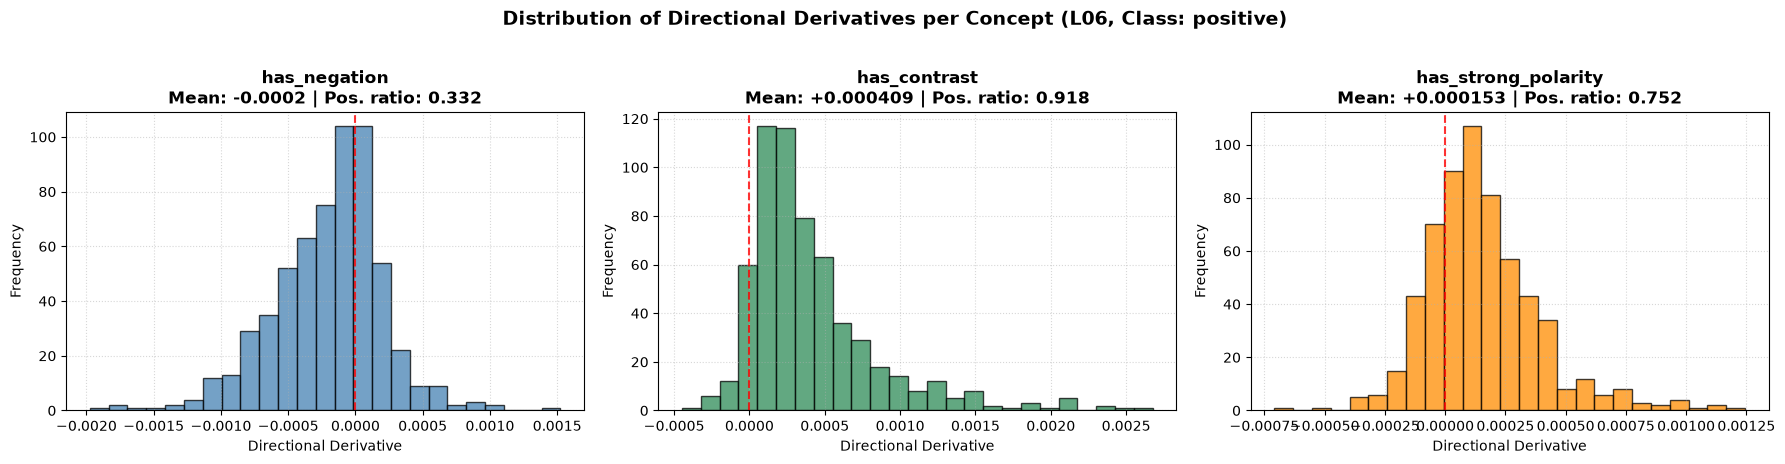

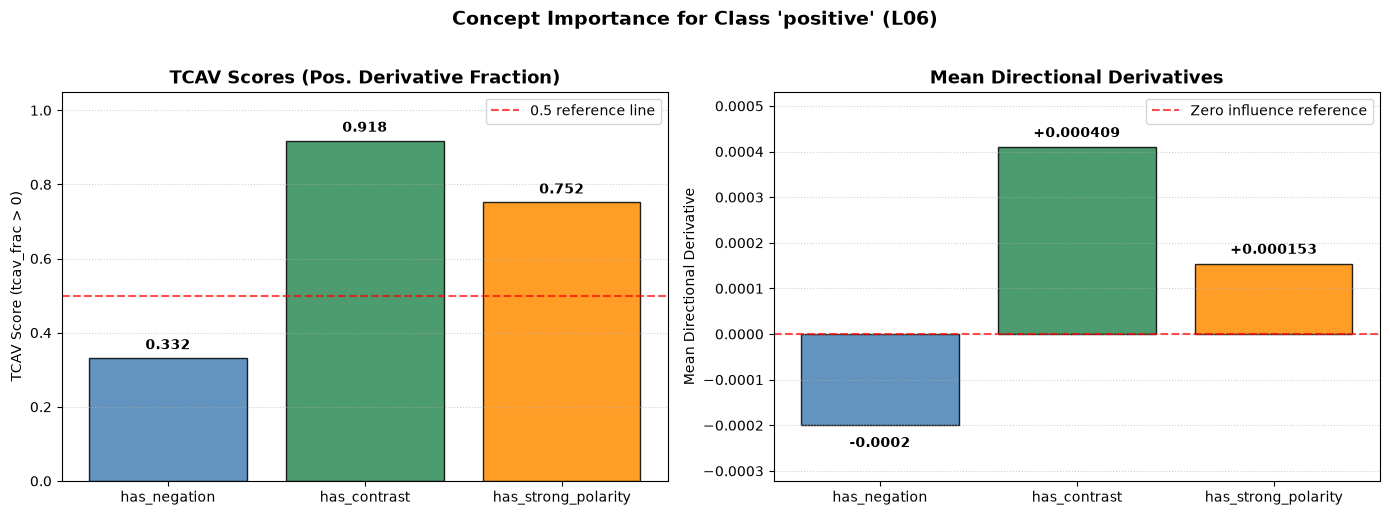

In [19]:
# Select target layer and class for detailed distribution plots
target_layer_str = f"L{TARGET_LAYERS[-1]:02d}"
target_cls_name = "positive" if "positive" in CLASS_MAP else list(CLASS_MAP.keys())[0]

derivs_list = [sample_derivatives[(target_layer_str, target_cls_name, c)] for c in concepts]
tcav_scores = [float((d > 0).mean()) for d in derivs_list]
mean_derivs = [float(np.mean(d)) for d in derivs_list]
colors = ['steelblue', 'seagreen', 'darkorange']

# 1. Distribution of directional derivatives per concept
fig, axes = plt.subplots(1, len(concepts), figsize=(6 * len(concepts), 4.5))
if len(concepts) == 1:
    axes = [axes]

for ax, concept, derivs, color in zip(axes, concepts, derivs_list, colors):
    ax.hist(derivs, bins=25, alpha=0.75, color=color, edgecolor='black')
    ax.axvline(0, color='red', linestyle='--', alpha=0.8, linewidth=1.5)
    mean_val = np.mean(derivs)
    pos_ratio = np.mean(derivs > 0)
    ax.set_title(f"{concept}\nMean: {mean_val:+.3g} | Pos. ratio: {pos_ratio:.3f}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Directional Derivative")
    ax.set_ylabel("Frequency")
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle(f"Distribution of Directional Derivatives per Concept ({target_layer_str}, Class: {target_cls_name})", 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 2. Side-by-side Bar plots for TCAV scores and Mean Derivatives (Lab 4.2 plot style)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: TCAV Scores (Fraction > 0)
bars1 = axes[0].bar(concepts, tcav_scores, color=colors, alpha=0.85, edgecolor='black')
axes[0].axhline(0.5, color='red', linestyle='--', alpha=0.7, label='0.5 reference line')
axes[0].set_ylim(0, 1.05)
axes[0].set_title("TCAV Scores (Pos. Derivative Fraction)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("TCAV Score (tcav_frac > 0)")
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

for bar, score in zip(bars1, tcav_scores):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
                 f'{score:.3f}', ha='center', va='bottom', fontweight='bold')

# Right plot: Mean Directional Derivatives
bars2 = axes[1].bar(concepts, mean_derivs, color=colors, alpha=0.85, edgecolor='black')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.7, label='Zero influence reference')
axes[1].set_title("Mean Directional Derivatives", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Mean Directional Derivative")
axes[1].legend(loc='upper right')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

for bar, val in zip(bars2, mean_derivs):
    axes[1].annotate(f'{val:+.3g}',
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     xytext=(0, 5 if val >= 0 else -8), textcoords='offset points',
                     ha='center', va='bottom' if val >= 0 else 'top', fontweight='bold')

axes[1].margins(y=0.2)
plt.suptitle(f"Concept Importance for Class '{target_cls_name}' ({target_layer_str})", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 11. Comprehensive Summary & Metrics Table Export

Summary logs output matching Lab 5a format and display of Marco's complete sensitivity dataframe across all layers, target classes, and concepts.

In [20]:
# Detailed concept sensitivity logging (Lab format)
print("\n" + "=" * 70)
print(f"DETAILED SENSITIVITY SUMMARY ({target_layer_str}, Target Class: '{target_cls_name}')")
print("=" * 70)

for concept_name, score, derivatives in zip(concepts, tcav_scores, derivs_list):
    positive = int(np.count_nonzero(derivatives > 0))
    negative = int(np.count_nonzero(derivatives < 0))
    zero = int(np.count_nonzero(derivatives == 0))
    n = len(derivatives)
    
    assert np.isclose(score, positive / n), "TCAV must equal the positive-derivative fraction."
    relation = "more than half" if score > 0.5 else "fewer than half" if score < 0.5 else "exactly half"
    mean_val = float(np.mean(derivatives))
    
    print(f"Concept '{concept_name}': {positive}/{n} positive, {negative} negative, {zero} zero derivatives.")
    print(f"  TCAV score = {score:.4f}: {relation} of eval texts have positive local sensitivity.")
    print(f"  Mean signed derivative = {mean_val:+.4g}; range = [{np.min(derivatives):+.4g}, {np.max(derivatives):+.4g}].\n")

print("=" * 70)
print(f"{'Concept':<22} {'TCAV Score':>12} {'Mean Deriv':>12} {'Pos. Ratio':>12}")
print("-" * 70)
for name, score, derivs in zip(concepts, tcav_scores, derivs_list):
    print(f"{name:<22} {score:>12.4f} {np.mean(derivs):>12.4g} {np.mean(derivs > 0):>12.4f}")

best_concept = concepts[int(np.argmax(tcav_scores))]
print(f"\nHighest positive-sensitivity concept: '{best_concept}' (TCAV = {max(tcav_scores):.4f})")
print("=" * 70)

# Display Marco's complete extended metrics dataframe
print("\n=== Complete Extended Sensitivity Metrics Table (All Layers & Classes) ===")
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)
display(sens_all_df)


DETAILED SENSITIVITY SUMMARY (L06, Target Class: 'positive')
Concept 'has_negation': 199/600 positive, 401 negative, 0 zero derivatives.
  TCAV score = 0.3317: fewer than half of eval texts have positive local sensitivity.
  Mean signed derivative = -0.0002001; range = [-0.001976, +0.001524].

Concept 'has_contrast': 551/600 positive, 49 negative, 0 zero derivatives.
  TCAV score = 0.9183: more than half of eval texts have positive local sensitivity.
  Mean signed derivative = +0.0004091; range = [-0.0004476, +0.002677].

Concept 'has_strong_polarity': 451/600 positive, 149 negative, 0 zero derivatives.
  TCAV score = 0.7517: more than half of eval texts have positive local sensitivity.
  Mean signed derivative = +0.0001533; range = [-0.0007089, +0.001245].

Concept                  TCAV Score   Mean Deriv   Pos. Ratio
----------------------------------------------------------------------
has_negation                 0.3317   -0.0002001       0.3317
has_contrast                 0.9183

,layer,target_class,concept,tcav_frac>0,rnd_frac>0,mean_sens,mean_rnd,sens(c=1),sens(c=0)
0,L01,0_negative,has_negation,0.1117,0.5625,-0.0026,0.0002,-0.0004,-0.0031
1,L01,0_negative,has_contrast,0.1217,0.5625,-0.0017,0.0002,-0.0004,-0.0018
2,L01,0_negative,has_strong_polarity,0.6167,0.5625,0.0012,0.0002,0.0034,0.0011
3,L01,1_neutral,has_negation,0.8917,0.4758,0.0013,-0.0000,0.0012,0.0013
4,L01,1_neutral,has_contrast,0.8733,0.4758,0.0008,-0.0000,0.0004,0.0008
5,L01,1_neutral,has_strong_polarity,0.0767,0.4758,-0.0021,-0.0000,-0.0027,-0.0021
6,L01,2_positive,has_negation,0.7583,0.4603,0.0016,-0.0002,-0.0005,0.0021
7,L01,2_positive,has_contrast,0.7600,0.4603,0.0011,-0.0002,0.0001,0.0012
8,L01,2_positive,has_strong_polarity,0.6200,0.4603,0.0011,-0.0002,-0.0009,0.0012
9,L02,0_negative,has_negation,0.1317,0.4466,-0.0035,-0.0001,0.0001,-0.0044


### Brief comment


It seems like the concept has_negation is very rarely present in the data.